In [3]:
import numpy as np
import pandas as pd
RSEED = 50

In [4]:
# Load data and remove unused text columns.
from pathlib import Path
data_path = Path("train.csv")
if not data_path.exists():
    data_path = Path("titanic/train.csv")
titanic_raw = pd.read_csv(data_path)
titanic_data = titanic_raw.copy()
titanic_data = titanic_data.drop(columns=["Name", "Ticket", "Cabin"])
# Fixed binary coding does not learn any statistics from the data.
sex_encoding = {"male": 0, "female": 1}
titanic_data["Sex"] = titanic_data["Sex"].map(sex_encoding)
assert titanic_data["Sex"].notna().all(), "Sex must be recorded as male or female."
# Keep missing values for imputation inside each training fold.
titanic_data.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Fare             0
Embarked         2
dtype: int64

In [5]:
# Train Test Split 
from sklearn.model_selection import train_test_split
# 80/20 train-test split using RSEED
train_df, test_df = train_test_split(titanic_data, test_size=0.2, random_state=RSEED)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (712, 9)
Test shape: (179, 9)


In [6]:

# Shared feature selection and preprocessing for all models.
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

feature_cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
numeric_cols = ["Age", "SibSp", "Parch", "Fare"]
binary_cols = ["Sex"]
categorical_cols = ["Pclass", "Embarked"]

X_train = train_df[feature_cols].copy()
y_train = train_df["Survived"].copy()
X_test = test_df[feature_cols].copy()
y_test = test_df["Survived"].copy()

shared_preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_cols),
    ("binary", "passthrough", binary_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])


def make_model_pipeline(model):
    """Give each model its own preprocessing, fitted inside each training fold."""
    return Pipeline([
        ("preprocess", clone(shared_preprocessor)),
        ("model", clone(model)),
    ])

In [7]:
from sklearn.model_selection import StratifiedKFold
# 5-fold cross-validation with shuffling and RSEED
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RSEED)
cv_splits = list(skf.split(X_train, y_train))
for fold, (train_idx, val_idx) in enumerate(cv_splits, 1):
    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]
    print(f"Fold {fold}: Train size = {len(fold_train)}, Val size = {len(fold_val)}")

Fold 1: Train size = 569, Val size = 143
Fold 2: Train size = 569, Val size = 143
Fold 3: Train size = 570, Val size = 142
Fold 4: Train size = 570, Val size = 142
Fold 5: Train size = 570, Val size = 142


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Candidate values for the inverse regularization strength
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]

cv_results = []

for C in C_values:
    fold_accuracies = []

    for train_idx, val_idx in cv_splits:
        # Split training and validation data
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_fold_val = X_train.iloc[val_idx]
        y_fold_val = y_train.iloc[val_idx]

        # Build logistic regression pipeline
        model = make_model_pipeline(
            LogisticRegression(
                penalty="l2",
                C=C,
                solver="lbfgs",
                max_iter=1000
            )
        )

        # Fit and evaluate
        model.fit(X_fold_train, y_fold_train)
        y_pred = model.predict(X_fold_val)

        fold_accuracies.append(
            accuracy_score(y_fold_val, y_pred)
        )

    cv_results.append({
        "C": C,
        "Mean CV Accuracy": np.mean(fold_accuracies),
        "Std CV Accuracy": np.std(fold_accuracies)
    })

# Compare results
cv_results = pd.DataFrame(cv_results)
print(cv_results)

# Select the best C
best_C = cv_results.loc[
    cv_results["Mean CV Accuracy"].idxmax(), "C"
]

print("Best C:", best_C)

          C  Mean CV Accuracy  Std CV Accuracy
0     0.001          0.682478         0.040785
1     0.010          0.726002         0.037970
2     0.100          0.806107         0.032059
3     1.000          0.796316         0.037686
4    10.000          0.796316         0.037686
5   100.000          0.797725         0.038033
6  1000.000          0.797725         0.038033
Best C: 0.1


In [ ]:
best_logistic = make_model_pipeline(
    LogisticRegression(
        penalty="l2",
        C=best_C,
        solver="lbfgs",
        max_iter=1000
    )
)

best_logistic.fit(X_train, y_train)



Test-set classification counts


,TP,FP,TN,FN
Logistic Regression,53,9,92,25



Held-out test results


,Test N,Accuracy,Precision,Recall,F1 Score,ROC AUC
Logistic Regression,179,0.8101,0.8548,0.6795,0.7571,0.8503


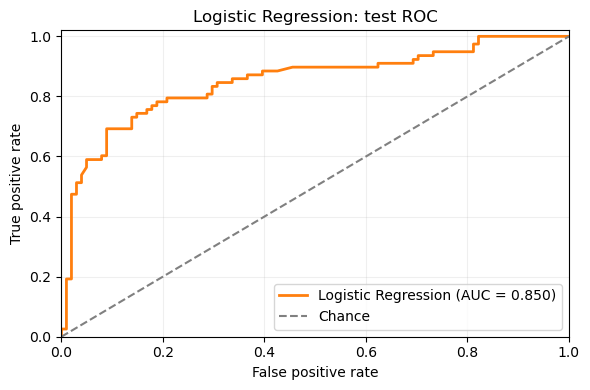

In [14]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)
import matplotlib.pyplot as plt


# Test-set predictions
log_test_predictions = best_logistic.predict(X_test)

# Predicted probabilities for the positive class (Survived = 1)
log_test_vote_shares = best_logistic.predict_proba(X_test)[:, 1]

# Confusion matrix
log_tn, log_fp, log_fn, log_tp = confusion_matrix(
    y_test, log_test_predictions
).ravel()

# Classification counts
log_classification_counts = pd.DataFrame([{
    "Model": "Logistic Regression",
    "TP": int(log_tp),
    "FP": int(log_fp),
    "TN": int(log_tn),
    "FN": int(log_fn),
}]).set_index("Model").rename_axis(None)

print("\nTest-set classification counts")
display(log_classification_counts)

# Test-set performance metrics
log_test_results = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Test N": len(y_test),
    "Accuracy": accuracy_score(y_test, log_test_predictions),
    "Precision": precision_score(
        y_test, log_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, log_test_predictions, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, log_test_predictions, zero_division=0
    ),
    "ROC AUC": roc_auc_score(
        y_test, log_test_vote_shares
    ),
}]).set_index("Model").rename_axis(None)

print("\nHeld-out test results")
display(log_test_results.round(4))

# ROC curve
log_fpr, log_tpr, _ = roc_curve(y_test, log_test_vote_shares)

log_fig, log_ax = plt.subplots(figsize=(6, 4))

log_ax.plot(
    log_fpr, log_tpr, color="tab:orange", linewidth=2,
    label=f"Logistic Regression (AUC = {log_test_results.loc['Logistic Regression', 'ROC AUC']:.3f})",
)

log_ax.plot(
    [0, 1], [0, 1], "--", color="gray", label="Chance"
)

log_ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="Logistic Regression: test ROC",
    xlim=(0, 1),
    ylim=(0, 1.02),
)

log_ax.legend(loc="lower right")
log_ax.grid(alpha=0.2)

log_fig.tight_layout()
plt.show()